# Single Parameter Analysis

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pysd


Load Data 

In [7]:
# Reads the vensim file.
model = pysd.read_vensim("SEIQR_risk.mdl") 

Stocks, Flows, Auxilliary

In [11]:
# List stocks, flows and auxiliary variables from the loaded PySD model

components = None

if hasattr(model, "components"):
    comp_attr = model.components
    components = comp_attr() if callable(comp_attr) else comp_attr
elif hasattr(model, "get_components"):
    components = model.get_components()
else:
    components = getattr(model, "_components", None)

if components is None:
    raise RuntimeError("Unable to access model components. Check model attributes via dir(model).")

# Robustly obtain items from the components object without assuming it's iterable
items = None

# Try dict-like items() first
if hasattr(components, "items"):
    try:
        items = list(components.items())
    except Exception:
        try:
            # some objects expose a callable items attribute differently
            items_attr = getattr(components, "items")
            if callable(items_attr):
                items = list(items_attr())
        except Exception:
            items = None

# If still not found, handle common shapes
if items is None:
    if isinstance(components, (list, tuple)):
        items = [(getattr(comp, "name", f"comp_{idx}"), comp) for idx, comp in enumerate(components)]
    else:
        # Try internal storage
        inner = getattr(components, "_components", None)
        if inner is not None:
            try:
                items = list(inner.items()) if hasattr(inner, "items") else [(getattr(comp, "name", f"comp_{idx}"), comp) for idx, comp in enumerate(inner)]
            except Exception:
                items = None

# Fallback: build items from accessible attributes (ignore private/dunder)
if items is None:
    try:
        items = list(components)
    except Exception:
        items = []
        for name in dir(components):
            if name.startswith("_"):
                continue
            try:
                obj = getattr(components, name)
            except Exception:
                continue
            # Avoid including methods and modules as components
            if callable(obj):
                continue
            items.append((name, obj))

def get_component_type(component):
    for attr_name in ("component_type", "type", "var_type", "component_kind"):
        if hasattr(component, attr_name):
            val = getattr(component, attr_name)
            if val is not None:
                return val
    return None

stocks = []
flows = []
auxiliaries = []

for name, comp in items:
    comp_type = get_component_type(comp)
    comp_type_str = str(comp_type).lower() if comp_type is not None else ""

    if "stock" in comp_type_str or getattr(comp, "is_stock", False):
        stocks.append(name)
    elif "flow" in comp_type_str or getattr(comp, "is_flow", False):
        flows.append(name)
    else:
        auxiliaries.append(name)

print("Stocks:")
print(sorted(stocks))
print()
print("Flows:")
print(sorted(flows))
print()
print("Auxiliary variables:")
print(sorted(auxiliaries))

NameError: Component 'items' not found in the model.

Sensitivity Analysis

c:\Users\adeolu.adekunle\.conda\envs\Adeolujoe\Lib\site-packages\pysd\py_backend\model.py:1145: UserWarning: Replacing a variable by a constant value.
  warnings.warn("Replacing a variable by a constant value.")


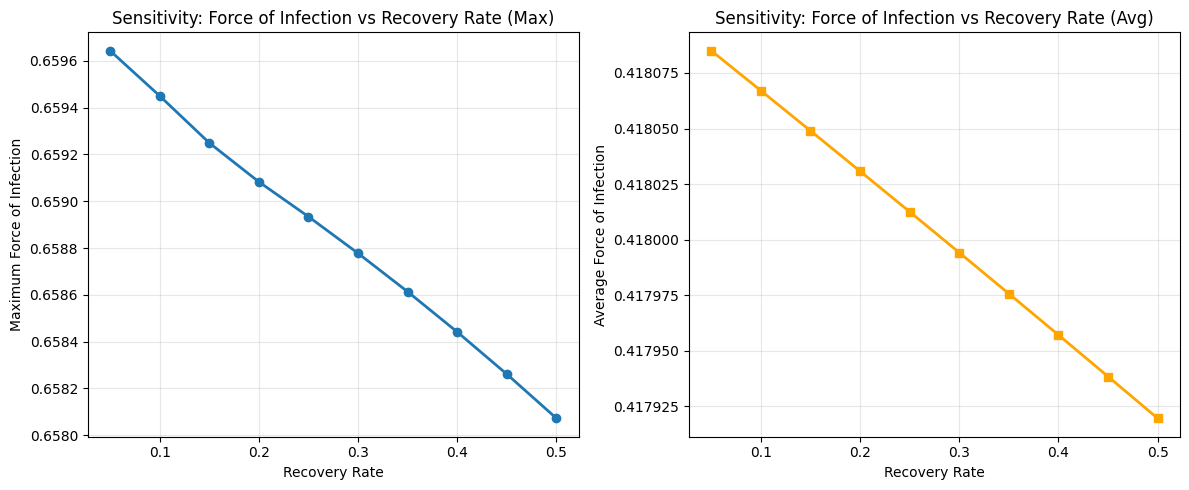

   Recovery Rate  Max Force of Infection  Avg Force of Infection
0           0.05                0.659644                0.418085
1           0.10                0.659450                0.418067
2           0.15                0.659249                0.418049
3           0.20                0.659083                0.418031
4           0.25                0.658934                0.418013
5           0.30                0.658777                0.417994
6           0.35                0.658613                0.417976
7           0.40                0.658441                0.417957
8           0.45                0.658260                0.417938
9           0.50                0.658072                0.417920


In [8]:
# Sensitivity analysis: Force of Infection vs Recovery Rate

# Define parameter ranges
recovery_rates = np.linspace(0.05, 0.5, 10)  # 10 steps for recovery rate

sensitivity_results = []

for rate in recovery_rates:
    params = {
        "Recovery Rate": rate
    }
    
    res = model.run(params=params)
    
    max_foi = res["Force of infection"].max()
    avg_foi = res["Force of infection"].mean()
    
    sensitivity_results.append({
        'Recovery Rate': rate,
        'Max Force of Infection': max_foi,
        'Avg Force of Infection': avg_foi
    })

# Convert to DataFrame for analysis
df_sensitivity = pd.DataFrame(sensitivity_results)

# Plot the results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(df_sensitivity['Recovery Rate'], df_sensitivity['Max Force of Infection'], marker='o', linewidth=2)
plt.xlabel('Recovery Rate')
plt.ylabel('Maximum Force of Infection')
plt.title('Sensitivity: Force of Infection vs Recovery Rate (Max)')
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(df_sensitivity['Recovery Rate'], df_sensitivity['Avg Force of Infection'], marker='s', linewidth=2, color='orange')
plt.xlabel('Recovery Rate')
plt.ylabel('Average Force of Infection')
plt.title('Sensitivity: Force of Infection vs Recovery Rate (Avg)')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(df_sensitivity)

# Correlation Plot

# Multiple Parameter Analysis

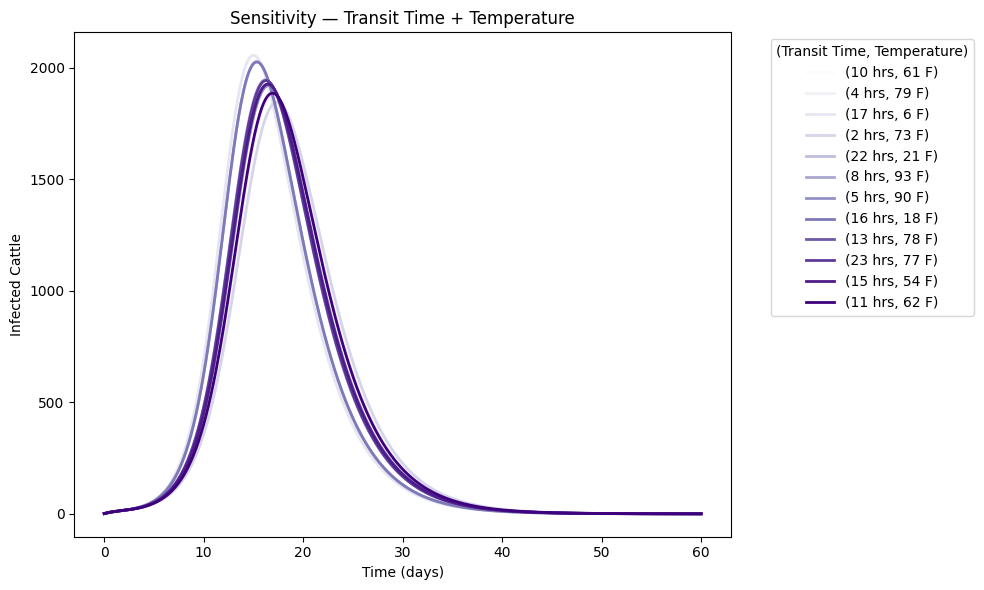

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pysd


# Same idea as the single-parameter simulation.
# Here you can simultaneously change multiple parameters and see the outcome.

num = {}

model = pysd.read_vensim("SEIQR_risk updated copy 3.mdl")

N = 12
stocks = ["Infected"]

# Generates random values
values1 = np.random.choice(np.arange(2,24), size=N, replace=False)
values2 = np.random.choice(np.arange(-8,105), size=N, replace=False)

# comment it if you don't want sorted pairings, meaning random pairings.

# values1.sort()
# values2.sort()

pairs = list(zip(values1, values2))

# Color map
cmap = plt.get_cmap("Purples")
colors = [cmap(i/(N-1)) for i in range(N)]

plt.figure(figsize=(10,6))

for i, (v1, v2) in enumerate(pairs):

    params = {
        "average_transit_time_hours": v1,
        "average_ambient_temperature_f": v2
    }

    res = model.run(params=params)

    max_infected = res[stocks[0]].max()
    num[(v1, v2)] = max_infected

    plt.plot(
        res.index,
        res[stocks[0]],
        color=colors[i],
        label=f"({v1} hrs, {v2} F)",
        linewidth=2
    )

plt.xlabel("Time (days)")
plt.ylabel("Infected Cattle")
plt.title(f"Sensitivity — Transit Time + Temperature")

plt.legend(
    title="(Transit Time, Temperature)",
    bbox_to_anchor=(1.05,1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

# Heatmap for interactions

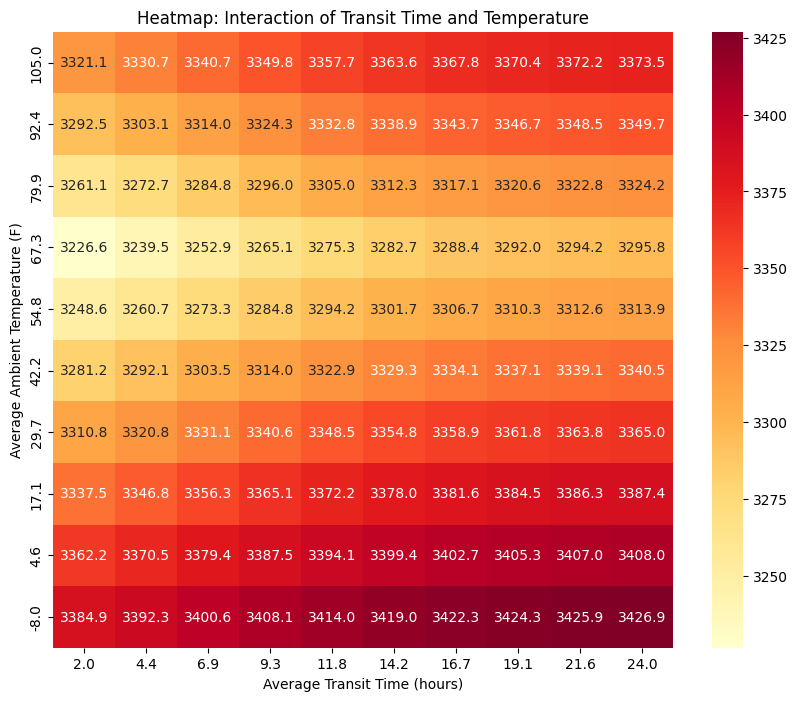

In [ ]:
import pandas as pd
import seaborn as sns

# This outputs a heatmap. Better visualization to show the interaction between BRD stressors.

# Define the range.
v1_range = np.linspace(2, 24, 10)   # 10 steps of transit time
v2_range = np.linspace(-8, 105, 10) # 10 steps of temperature

grid_results = []

# Run nested loops to get every combination (Interaction Grid)
for v1 in v1_range:
    for v2 in v2_range:
        params = {
            "average_transit_time_hours": v1,
            "average_ambient_temperature_f": v2
        }
        res = model.run(params=params)
        max_inf = res["Infected"].max()

        grid_results.append({'Transit': round(v1, 1), 'Temp': round(v2, 1), 'Infected': max_inf})

# Format into a pivot table for the heatmap
df_grid = pd.DataFrame(grid_results)
pivot_table = df_grid.pivot(index='Temp', columns='Transit', values='Infected')

# Plot
plt.figure(figsize=(10, 8))
sns.heatmap(pivot_table, annot=True, cmap='YlOrRd', fmt=".1f")
plt.title("Heatmap: Interaction of Transit Time and Temperature")
plt.xlabel("Average Transit Time (hours)")
plt.ylabel("Average Ambient Temperature (F)")
plt.gca().invert_yaxis()
plt.show()